# Chapter 2 · Classical image processing

*Book 27 · Deep Learning on Images & Signals · Shelf VII*

**Builds on:** [Chapter 1](01-images-as-arrays.ipynb) -- images as arrays, grey levels.
**You will:** write a convolution by hand and check it against OpenCV, blur and sharpen, find
edges, and binarise a photo with uneven light -- the operations a convolutional network will
later learn on its own.

A **convolution** slides a small grid of weights (a *kernel*) over the image and replaces every
pixel by the weighted sum of its neighbourhood. Blur, sharpen and edge detection are all just
different kernels.

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

from ds_toolbox import qrbills as qb
from ds_toolbox import viz

viz.use_style()
bill = qb.generate_bills(1, seed=2)[0]
clean = cv2.cvtColor(qb.render(bill), cv2.COLOR_RGB2GRAY)
photo = cv2.cvtColor(qb.distort(qb.render(bill), 2, seed=3), cv2.COLOR_BGR2GRAY)
crop = (slice(30, 330), slice(690, 1240))

## A convolution, by hand

In [2]:
def convolve(image, kernel):
    """Correlate ``image`` with ``kernel`` (what image libraries call 'convolution'), edges replicated."""
    k = kernel.shape[0] // 2
    padded = np.pad(image.astype(float), k, mode="edge")
    out = np.zeros(image.shape, dtype=float)
    for dy in range(-k, k + 1):
        for dx in range(-k, k + 1):
            out += kernel[dy + k, dx + k] * padded[k + dy:k + dy + image.shape[0], k + dx:k + dx + image.shape[1]]
    return out

box = np.full((5, 5), 1 / 25)
mine = convolve(clean, box)
lib = cv2.filter2D(clean.astype(float), -1, box, borderType=cv2.BORDER_REPLICATE)
print("largest difference to OpenCV:", np.abs(mine - lib).max().round(10))

largest difference to OpenCV: 0.0


The loop is over the 25 kernel positions, not over the 768 800 pixels: each position is one
shifted copy of the whole image, weighted and summed. That is also how a GPU thinks about it.

## Blur and sharpen

A **Gaussian** kernel blurs smoothly. **Unsharp masking** sharpens by subtracting the blur:
`sharp = image + a * (image - blur)` -- it exaggerates whatever the blur removed, which is the
detail.

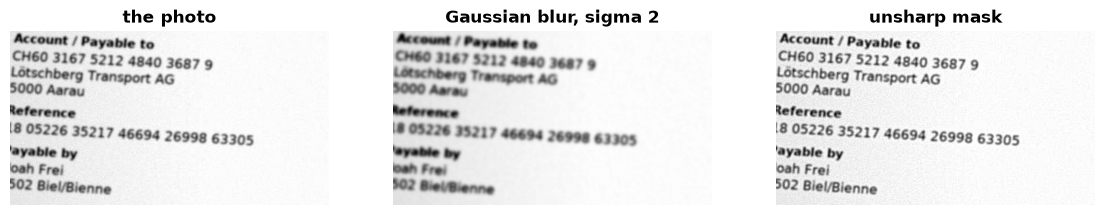

In [3]:
blur = cv2.GaussianBlur(photo, (0, 0), 2)
sharp = cv2.addWeighted(photo, 1.8, blur, -0.8, 0)
fig, axes = plt.subplots(1, 3, figsize=(14, 3))
for ax, im, title in zip(axes, [photo, blur, sharp], ["the photo", "Gaussian blur, sigma 2", "unsharp mask"],
                         strict=True):
    ax.imshow(im[crop], cmap="gray")
    ax.set_title(title)
    ax.axis("off")

## Edges

The **Sobel** kernels estimate the gradient -- how fast the grey level changes left to right
and top to bottom. Its magnitude is large on edges. **Canny** thins those to one-pixel lines and
keeps only the connected strong ones.

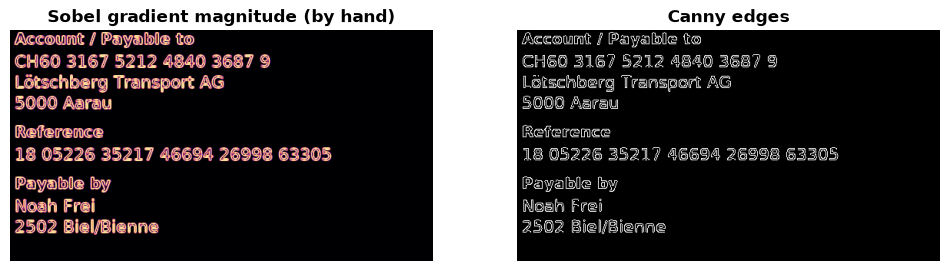

In [4]:
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=float)
gx = convolve(clean, sobel_x)
gy = convolve(clean, sobel_x.T)
magnitude = np.hypot(gx, gy)
edges = cv2.Canny(clean, 50, 150)
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
axes[0].imshow(magnitude[crop], cmap="magma")
axes[0].set_title("Sobel gradient magnitude (by hand)")
axes[1].imshow(edges[crop], cmap="gray")
axes[1].set_title("Canny edges")
for a in axes:
    a.axis("off")

## From grey to black and white

A QR decoder and an OCR engine both want ink separated from paper. **Otsu's method** picks the
one threshold that best splits the histogram's two peaks (chapter 1). On a photo with a light
gradient one threshold cannot fit both sides; an **adaptive** threshold compares every pixel
with its own neighbourhood instead.

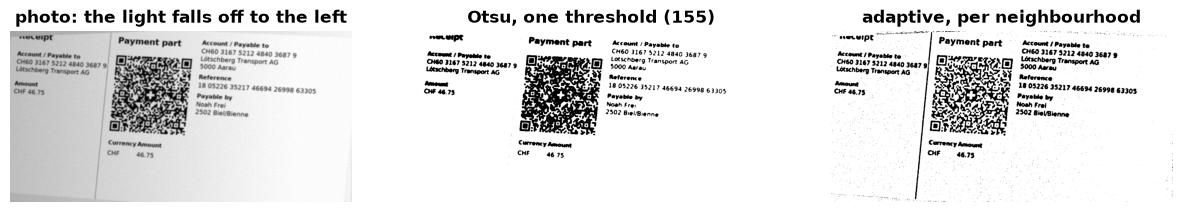

In [5]:
otsu_t, otsu = cv2.threshold(photo, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
adaptive = cv2.adaptiveThreshold(photo, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 51, 10)
fig, axes = plt.subplots(1, 3, figsize=(15, 3))
axes[0].imshow(photo, cmap="gray")
axes[0].set_title("photo: the light falls off to the left")
axes[1].imshow(otsu, cmap="gray")
axes[1].set_title(f"Otsu, one threshold ({otsu_t:.0f})")
axes[2].imshow(adaptive, cmap="gray")
axes[2].set_title("adaptive, per neighbourhood")
for a in axes:
    a.axis("off")

## Morphology

After binarising, small specks and gaps remain. **Opening** (erode, then dilate) removes specks
smaller than the structuring element; **closing** (dilate, then erode) fills small gaps. Larger
shapes survive -- but not untouched: a stroke thinner than the element goes with the specks.

In [6]:
speckled = adaptive.copy()
rng = np.random.default_rng(0)
noise = rng.random(speckled.shape) < 0.01
speckled[noise] = 0
kernel = np.ones((3, 3), np.uint8)
ink = adaptive == 0
opened = cv2.morphologyEx(255 - speckled, cv2.MORPH_OPEN, kernel) > 0
specks = noise & ~ink
print(f"specks removed: {1 - (opened & specks).sum() / specks.sum():.0%} "
      f"| real ink kept: {(opened & ink).sum() / ink.sum():.0%}")

specks removed: 99% | real ink kept: 95%


The numbers show the trade: the specks go, and so does a share of the real ink -- the
thinnest parts of the characters. Choosing the element's size is choosing that balance.

## What to remember

- A convolution is a weighted sum over a neighbourhood; the kernel decides what it does.
- Sharpening subtracts a blur. Edges are large gradients.
- Binarise adaptively when the light is uneven. Clean up with opening and closing.

## Exercises

1. Write the 3 x 3 Laplacian kernel and apply it with `convolve`. What does it respond to?
2. Vary the adaptive threshold's block size from 11 to 101. What breaks at each end?
3. Open with a 5 x 5 kernel instead of 3 x 3. Which characters lose strokes?

**Next:** [Chapter 3 · Geometry and distortion](03-geometry-and-distortion.ipynb)